# Les députés représentent-ils leurs électeurs ?

*Projet réalisé par Leana Ghezali et Selima Skhiri — Python pour la data science*

**Introduction.** La question de la représentativité occupe une place centrale dans le débat politique contemporain : au-delà de l'expression du vote, dans quelle mesure les élus sont-ils à l'image de la population ? Dans ce projet, nous croisons les données individuelles des députés de l'Assemblée nationale avec les indicateurs socio-économiques de leurs circonscriptions afin d'objectiver statistiquement les similitudes et les écarts entre représentants et représentés.

**Problématique.** Nous comparons le profil de chaque député (âge, genre, profession, groupe politique) à celui de sa circonscription (indicateurs INSEE), pour mesurer dans quelle mesure l'Assemblée ressemble aux territoires qu'elle représente.

## Résumé des résultats

| Dimension | Résultat principal | Solidité |
|---|---|---|
| **Profession** | 70,8 % des députés classés sont cadres ou de profession intellectuelle supérieure, contre 16,0 % de la population active. Employés et ouvriers : 6,5 % des députés, près de la moitié des actifs. | Très robuste : l'écart (≈ 55 points) reste énorme dans les hypothèses les plus défavorables sur les libellés non classés (section 5.3). |
| **Âge** | Lien positif mais faible entre l'âge du député et l'âge médian de sa circonscription (r = 0,18, soit ≈ 3 % de variance expliquée). | Significatif, effet faible. |
| **Genre** | 38 % de femmes parmi les députés ; leurs circonscriptions sont un peu plus urbaines et favorisées (+3,2 points de cadres, ≈ +900 € de niveau de vie médian). | Écarts modestes ; seuls quatre indicateurs résistent à la correction des tests multiples (section 2.2 et 5.2). |
| **Groupe politique** | Les circonscriptions diffèrent fortement selon le groupe du député (Kruskal-Wallis, p ≈ 7·10⁻²³) ; plus un groupe compte de femmes, plus ses circonscriptions comptent de cadres (ρ de Spearman = 0,91). | Fort au niveau des groupes (huit observations seulement) ; confirmé par un test exact de permutation et par un retrait successif de chaque groupe (section 5.4). |

Les sections 3 (cartes) et 5 (robustesse) ont été ajoutées pour vérifier que ces résultats ne dépendent ni d'un choix de test, ni du recodage des professions, ni d'un groupe ou d'une circonscription particulière.

# 1. Données
## 1.1 Sources

| Source | Contenu | Accès |
|---|---|---|
| INSEE, indicateurs par circonscription législative (2022) | 124 indicateurs socio-économiques | Fichier Excel téléchargé |
| INSEE, composition des circonscriptions | Correspondance communes - circonscriptions | Fichier Excel téléchargé |
| Députés actifs de l'Assemblée nationale | Âge, genre, profession, groupe, scores parlementaires | API data.gouv.fr |
| Contours des circonscriptions législatives (data.gouv.fr, Jérôme Desboeufs, Licence Ouverte 2.0) | Géométries pour les cartes | GeoJSON téléchargé |

Les fichiers bruts sont « gelés » dans `data/data_brut` pour que le projet reste rejouable si les sites changent.

In [1]:
from extraction_donnees import charger_donnees
from jointures import joindre_deputes_insee
from descriptif import (
    preparer_deputes, tableau_groupes, valeurs_manquantes,
    graphique_deputes, graphique_insee,
)

deputes, insee_indic, insee_compo, dico_insee = charger_donnees()
deputes = preparer_deputes(deputes)

print("Députés :", deputes.shape)
print("Indicateurs INSEE :", insee_indic.shape)
print("Composition communes-circonscriptions :", insee_compo.shape)

Députés : (574, 29)
Indicateurs INSEE : (567, 125)
Composition communes-circonscriptions : (35150, 8)


## 1.2 Nettoyage

Les données brutes n'étaient pas exploitables telles quelles :

- **Fichier INSEE des indicateurs** : les données sont dans le premier onglet, précédées de 7 lignes de métadonnées. La fonction `lire_excel_insee` prend donc l'onglet et la ligne d'en-tête en paramètres.
- **Clé de jointure `code_circo`** : l'INSEE utilise 5 caractères (`75018`), la base des députés les départements sur 3 chiffres et les circonscriptions sur 2. Nous avons harmonisé les deux au format INSEE.
- **Corse** : `2a001` côté députés, `2A001` côté INSEE, d'où un passage en majuscules.
- **Saint-Barthélemy** : l'INSEE la regroupe avec Saint-Martin (`97801`), le code `97701` a été rattaché à celle-ci.
- **Valeurs `s` et `nd`** de l'INSEE (secret statistique, non déterminé) : converties en valeurs manquantes.

In [2]:
df = joindre_deputes_insee(deputes, insee_indic)

print("Forme de la table jointe :", df.shape)
print(df["indicateur_present"].value_counts())
print(sorted(df.loc[~df["indicateur_present"], "code_circo"]))

Forme de la table jointe : (574, 154)
indicateur_present
True     563
False     11
Name: count, dtype: int64
['99001', '99002', '99003', '99004', '99005', '99006', '99007', '99008', '99009', '99010', '99011']


## 1.3 Jointure

La jointure est faite à gauche sur `code_circo` : sur 574 députés, **563 ont les indicateurs INSEE de leur circonscription**. Les 11 restants sont les circonscriptions des Français de l'étranger (`99001` à `99011`), pour lesquelles l'INSEE ne publie pas d'indicateurs. Nous les conservons avec des valeurs manquantes, car ils restent utiles pour les statistiques sur les députés eux-mêmes.

Côté INSEE, trois circonscriptions n'ont pas de député dans la base : l'Aube (2e), la Charente-Maritime (5e) et la Gironde (11e). Leurs titulaires ont été élus sénateurs fin septembre 2026 et ont été remplacés par leurs suppléants, qui ne figurent pas encore dans le fichier des députés téléchargé le 14 novembre 2026. La ligne `00000` de l'INSEE est une moyenne nationale, pas une circonscription : elle est exclue.

## 1.4 Description des données

### Les députés

,effectif,age_moyen,part_femmes
groupeAbrev,,,
RN,121,50.2,32.2
EPR,90,53.1,50.0
LFI-NFP,70,44.3,42.9
SOC,68,56.2,41.2
DR,46,54.5,30.4
ECOS,38,49.8,47.4
DEM,37,57.7,40.5
HOR,35,55.8,34.3
LIOT,24,59.4,25.0


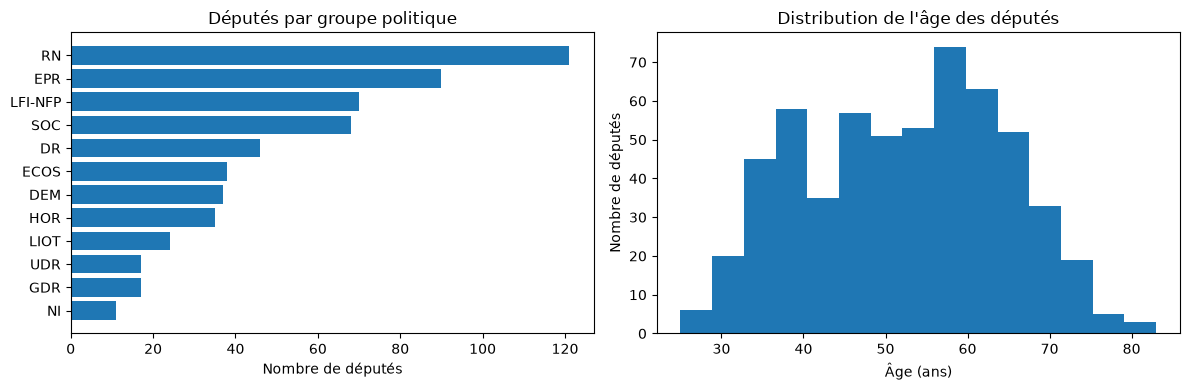

In [3]:
display(tableau_groupes(deputes))
graphique_deputes(deputes);

L'Assemblée compte 574 députés actifs répartis en 12 groupes, dont 38 % de femmes (220). Le RN (121 députés) et EPR (90) sont les groupes les plus nombreux. Trois groupes (GDR, UDR, NI) comptent moins de 20 députés : toute moyenne calculée sur eux sera peu fiable.

L'âge moyen des députés est d'environ 52 ans, mais il varie fortement selon les groupes : de 44 ans pour LFI-NFP et l'UDR à 59 ans pour LIOT. La parité varie aussi beaucoup, de 50 % de femmes chez EPR à 18 % à l'UDR. Ces écarts entre groupes justifient de ne pas traiter les députés comme un ensemble homogène dans la suite.

In [4]:
display(valeurs_manquantes(deputes))

,nb,pct
website,363,63.2
facebook,257,44.8
twitter,218,38.0
scoreParticipationSpecialite,4,0.7
scoreLoyaute,1,0.2
scoreMajorite,1,0.2


Les valeurs manquantes de la base des députés concernent surtout les réseaux sociaux et le site web (38 % à 63 %), variables que nous n'utiliserons pas. Les scores parlementaires sont quasi complets (1 à 4 valeurs manquantes sur 574).

### Les indicateurs INSEE

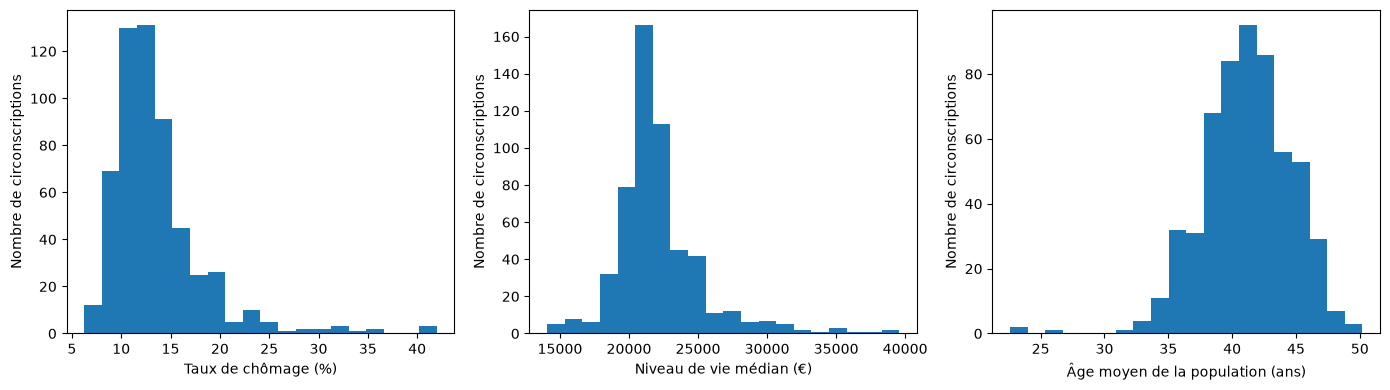

In [5]:
graphique_insee(df);

Les circonscriptions diffèrent nettement. Le taux de chômage (calculé comme chômeurs / population active, au sens du recensement, donc plus élevé que le taux officiel) a une médiane de 12,6 % et va de 6,2 % à 42 %. Les valeurs les plus élevées sont toutes en outre-mer (Mayotte, Guyane, La Réunion : de 36 % à 42 %), ce qui en fait des cas atypiques. Le niveau de vie médian va de 14 070 € à 39 590 € (médiane 21 590 €). L'âge moyen de la population, autour de 41 ans, est bien inférieur à celui des députés, mais les deux ne sont pas strictement comparables (l'âge INSEE inclut les enfants). Le niveau de vie médian est manquant pour 16 circonscriptions, toutes situées en outre-mer, que la source (Filosofi) ne semble pas couvrir.

# 2. Le député ressemble-t-il à sa circonscription ?

Cette section compare, un critère après l'autre, le profil du député à celui de sa circonscription. Les cartes de la section 3 donnent la dimension géographique, et la section 5 éprouve la robustesse des résultats.

## 2.1 Âge

         age  dec50  ecart_age
count  563.0  563.0      563.0
mean    52.2   41.4       10.8
std     12.2    5.1       12.4
min     25.0   17.0      -19.0
25%     42.0   38.0        2.0
50%     53.0   42.0       12.0
75%     61.0   45.0       19.0
max     83.0   55.0       41.0
toutes circonscriptions    0.17
métropole seule            0.18
dtype: float64
(np.float64(0.17849904160116345), np.float64(3.234018329464958e-05))


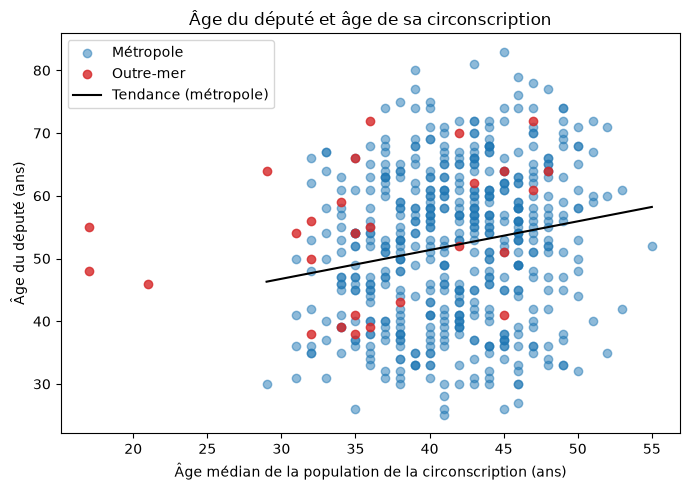

In [6]:
from representativite import preparer_comparaison, correlations_age, graphique_age

comp = preparer_comparaison(df)
print(comp[["age", "dec50", "ecart_age"]].describe().round(1))
print(correlations_age(comp).round(2))
graphique_age(comp);

from representativite import test_correlation_age
print(test_correlation_age(comp))

### Âge du député et âge de sa circonscription

Pour chaque circonscription métropolitaine et d'outre-mer disposant d'indicateurs INSEE (563 sur 574), nous rapprochons l'âge du député de l'âge médian de la population de sa circonscription. Les deux ne sont pas directement comparables : la population INSEE inclut les enfants, ce qui explique que l'écart moyen soit positif (environ 11 ans). Seule la variation de cet écart entre circonscriptions est donc interprétable.

Le nuage de points montre un lien positif mais faible : la corrélation est de 0,17 sur l'ensemble des circonscriptions et de 0,18 en métropole, où elle est statistiquement significative (test de Pearson, p-value < 0,001). L'âge médian de la circonscription n'explique ainsi qu'environ 3 % de la variation de l'âge des députés. Dans une circonscription d'âge médian donné, on trouve des députés de 25 à 83 ans. Les circonscriptions d'outre-mer, nettement plus jeunes (âge médian de 17 à 21 ans pour trois d'entre elles), ne modifient pas ce constat.

Nos données suggèrent donc que l'âge des députés dépend peu de celui de leurs électeurs. Cette corrélation décrit des circonscriptions, et ne dit rien du comportement des électeurs ni des partis dans le choix des candidats.

**Précision sur l'incertitude.** Avec 536 circonscriptions métropolitaines, la corrélation de 0,18 a un intervalle de confiance à 95 % (transformation de Fisher) d'environ [0,10 ; 0,26] : même la borne haute reste un lien faible (moins de 7 % de variance expliquée). Un test de rang (Spearman) et un intervalle bootstrap sont calculés en section 5.1 pour vérifier que ce constat ne dépend pas de la forme de la relation ni de quelques valeurs extrêmes.

## 2.2 Genre

In [7]:
from representativite import comparer_genre

tab_genre = comparer_genre(comp)
print("Effectifs (femmes, hommes) :", tab_genre.attrs["effectifs"])
display(tab_genre.round(3))

Effectifs (femmes, hommes) : (209, 327)


,moyenne_femmes,moyenne_hommes,ecart,p_value
indicateur,,,,
Part de la population dans un pôle urbain (%),54.352,47.537,6.815,0.013
Part de la population en commune rurale non périurbaine (%),12.682,16.631,-3.949,0.019
Niveau de vie médian (€),22819.426,21913.333,906.093,0.003
Taux de pauvreté (%),14.279,14.787,-0.508,0.301
Part de cadres parmi les actifs (%),18.069,14.874,3.195,0.000
Part d'ouvriers parmi les actifs (%),20.058,22.763,-2.705,0.000
Part d'actifs diplômés bac+5 ou plus (%),15.715,12.422,3.293,0.000
Taux de chômage (%),12.693,13.118,-0.424,0.194
Âge médian de la population (ans),41.177,42.058,-0.881,0.028


### Genre du député et profil de la circonscription

Nous comparons, en métropole (536 circonscriptions : 209 élues femmes, 327 élus hommes), les caractéristiques des circonscriptions selon le genre du député. L'outre-mer et les Français de l'étranger sont exclus, car leurs profils sont très atypiques et plusieurs indicateurs y sont absents. Les groupes sont comparés par un test de Mann-Whitney, qui ne suppose pas de distribution normale.

Les circonscriptions des députées sont plus urbaines et plus favorisées : elles comptent en moyenne 3,2 points de cadres de plus (18,1 % contre 14,9 %), 3,3 points de diplômés bac+5 de plus, 2,7 points d'ouvriers de moins, et un niveau de vie médian supérieur d'environ 900 € (22 800 € contre 21 900 €). Ces quatre écarts restent significatifs après correction pour les tests multiples (seuil de Bonferroni d'environ 0,006). La part de population en pôle urbain (+6,8 points), la part de ruralité (−3,9 points) et l'âge médian (−0,9 an) vont dans le même sens mais ne résistent pas à cette correction : nous les considérons comme des tendances. Le taux de pauvreté et le taux de chômage ne diffèrent pas significativement.

Ces écarts sont modestes en valeur absolue et décrivent des moyennes : les deux groupes de circonscriptions se recouvrent largement. Ils ne montrent pas que le genre « cause » le profil de la circonscription. Une explication possible, que nous n'avons pas testée, tient à la géographie des partis : les groupes qui présentent davantage de femmes pourraient être mieux implantés dans les territoires urbains et aisés.

In [8]:
from representativite import comparer_genre_intra_groupe

tab_intra = comparer_genre_intra_groupe(comp)
print("Groupes gardés :", tab_intra.attrs["groupes"])
print("Circonscriptions :", tab_intra.attrs["effectif"])
display(tab_intra.round(3))

Groupes gardés : ['DEM', 'DR', 'ECOS', 'EPR', 'HOR', 'LFI-NFP', 'RN', 'SOC']
Circonscriptions : 480


,ecart_intra_groupe,p_value
indicateur,,
Part de cadres parmi les actifs (%),1.895,0.046
Part d'actifs diplômés bac+5 ou plus (%),1.990,0.065
Part d'ouvriers parmi les actifs (%),-1.882,0.001
Niveau de vie médian (€),685.165,0.051
Part de la population dans un pôle urbain (%),3.958,0.075


#### Une différence due à la géographie des partis ?

Les femmes ne sont pas réparties au hasard entre les groupes politiques, et les groupes sont inégalement implantés selon les territoires. Pour savoir si l'écart précédent reflète seulement cela, nous retirons de chaque indicateur la moyenne du groupe du député, puis nous comparons les femmes et les hommes sur cet écart « interne au groupe ». Nous gardons les huit groupes comptant au moins 20 députés en métropole (480 circonscriptions), car la moyenne d'un petit groupe est trop fragile, et nous testons les cinq indicateurs les plus marqués pour limiter les tests multiples.

Les écarts se réduisent, de 25 % à 40 % selon l'indicateur, mais gardent le même signe : à groupe politique égal, les députées sont encore élues dans des circonscriptions comptant environ 1,9 point de cadres de plus, 1,9 point d'ouvriers de moins, 2,0 points de diplômés bac+5 de plus et un niveau de vie médian supérieur d'environ 685 €. Seul l'écart sur la part d'ouvriers résiste à la correction de Bonferroni (seuil de 0,01) ; les autres sont des tendances (p-values de 0,046 à 0,075).

La géographie des partis explique donc une partie de la différence, mais probablement pas toute. Cette conclusion reste prudente : l'échantillon est réduit par rapport à l'analyse précédente, et nous ne contrôlons ni l'ancienneté du député ni le type de scrutin.

## 2.3 Catégorie socioprofessionnelle

In [9]:
from professions import ajouter_categorie_job

deputes = ajouter_categorie_job(deputes)
display(deputes["csp_depute"].value_counts().to_frame("effectif"))

,effectif
csp_depute,
cad,347
art,55
int,40
non_classe,33
inactif,29
emp,27
politique,22
agr,16
ouv,5


Députés classés : 490


,deputes,population_active,ecart
Agriculteurs exploitants,3.3,1.4,1.8
"Artisans, commerçants, chefs d'entreprise",11.2,6.3,4.9
Cadres et prof. intellectuelles supérieures,70.8,16.0,54.8
Professions intermédiaires,8.2,24.6,-16.4
Employés,5.5,28.4,-22.8
Ouvriers,1.0,21.4,-20.4


,effectif,part_deputes_cadres,part_cadres_circo
quartile_cadres,,,
Q1 (moins de cadres),120,65.8,8.3
Q2,111,71.2,11.0
Q3,112,70.5,15.3
Q4 (plus de cadres),114,75.4,29.5


p-value (chi2) : 0.45402189372534496


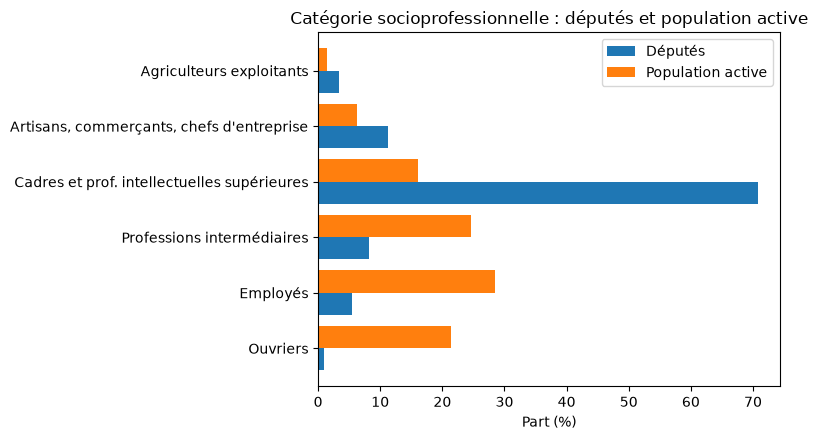

In [10]:
from professions import ajouter_categorie_job
from representativite import comparer_csp, graphique_csp, part_cadres_par_quartile

tab_csp = comparer_csp(ajouter_categorie_job(deputes), insee_indic)
print("Députés classés :", tab_csp.attrs["effectif"])
display(tab_csp)
graphique_csp(tab_csp);

comp_csp = ajouter_categorie_job(comp)
quartiles = part_cadres_par_quartile(comp_csp)
display(quartiles)
print("p-value (chi2) :", quartiles.attrs["p_value"])

### Catégorie socioprofessionnelle des députés

Nous recodons la profession déclarée de chaque député en six grandes catégories comparables à celles de l'INSEE (règles dans `professions.py`) : la nomenclature PCS lorsque la profession est codée (20 % des députés), des règles par mots-clés sinon. Sur 574 députés, 490 sont classés ; 84 sont exclus de la comparaison (22 collaborateurs ou membres de cabinets, 29 personnes sans activité ou retraitées sans ancien métier connu, 33 libellés trop ambigus).

Les cadres et professions intellectuelles supérieures représentent 70,8 % des députés classés, contre 16,0 % de la population active. À l'inverse, les employés (5,5 % contre 28,4 %) et les ouvriers (1,0 % contre 21,4 %) sont très peu présents : à eux deux, ils forment près de la moitié des actifs mais 6,5 % des députés. Les professions intermédiaires sont également sous-représentées (8,2 % contre 24,6 %). Les artisans, commerçants et chefs d'entreprise (11,2 % contre 6,3 %) et les agriculteurs exploitants (3,3 % contre 1,4 %) sont un peu surreprésentés, mais les effectifs sont faibles (16 agriculteurs et 5 ouvriers parmi les députés classés), ce qui rend ces parts fragiles.

Cette surreprésentation ne dépend pas de la circonscription : la part de députés cadres est de 66 % dans le quart des circonscriptions comptant le moins de cadres et de 75 % dans celui qui en compte le plus, mais cette différence n'est pas significative (test du chi2, p = 0,45). Même dans les territoires où les cadres sont rares, les élus sont très majoritairement cadres.

Ces résultats reposent sur la profession déclarée par les députés, qui peut valoriser leur parcours, et sur un recodage en partie subjectif (règles détaillées dans le code, 5,7 % de libellés non classés).

## 2.4 Groupe politique

In [14]:
from representativite import profil_par_groupe

tab_groupes = profil_par_groupe(comp)
display(tab_groupes)
print("p-value (Kruskal-Wallis) :", tab_groupes.attrs["p_kruskal"])

,effectif,part_femmes,part_cadres_circo,niveau_vie_median
groupeAbrev,,,,
ECOS,37,48.6,23.1,22644.6
EPR,78,52.6,22.1,24899.0
LFI-NFP,67,44.8,18.7,20759.9
SOC,63,42.9,18.3,22684.8
HOR,35,34.3,15.8,23323.7
DEM,35,42.9,15.2,22930.0
DR,46,30.4,13.9,22744.6
RN,119,31.9,10.6,20951.5


p-value (Kruskal-Wallis) : 7.308025280017948e-23


In [15]:
from representativite import correlation_groupes

r, p = correlation_groupes(tab_groupes)
print(f"Corrélation de Spearman : {r:.2f} (p = {p:.3f})")

Corrélation de Spearman : 0.91 (p = 0.002)


Sur les huit groupes, la corrélation de rang (Spearman) entre la part de femmes et la part moyenne de cadres des circonscriptions est de 0,91 (p = 0,002) : les groupes qui comptent le plus de femmes sont ceux dont les circonscriptions comptent le plus de cadres. Ce résultat repose sur huit groupes seulement et décrit des moyennes de groupe : il ne permet pas de conclure sur les députés pris individuellement. Il s'accorde avec l'analyse intra-groupe de la section précédente, où l'écart entre députées et députés se réduisait de 25 % à 40 % une fois la moyenne du groupe retirée, sans disparaître. La géographie des partis semble donc expliquer une partie de l'écart de genre observé entre circonscriptions, mais pas sa totalité.

# 3. Cartographie

Les cartes sont produites par `cartes.py` à partir des contours des circonscriptions (GeoJSON, projections Lambert-93 pour la métropole et UTM locale pour chaque territoire d'outre-mer). Un encart agrandit **Paris et la petite couronne** (départements 75, 92, 93, 94), dont les circonscriptions sont trop petites pour être lisibles à l'échelle nationale, et chaque territoire d'outre-mer a son propre encart. L'échelle de couleurs et la légende sont communes à tous les panneaux, pas l'échelle géographique.

**Circonscriptions sans couleur ou en gris.** Les circonscriptions en gris (Aube 2e, Charente-Maritime 5e, Gironde 11e) n'ont pas de député dans notre base (section 1.3). Sept circonscriptions d'outre-mer (Saint-Martin/Saint-Barthélemy, Wallis-et-Futuna, Polynésie française, Nouvelle-Calédonie) n'ont pas de contour dans le fichier utilisé, et les 11 circonscriptions des Français de l'étranger ne sont pas cartographiables. Les cartes décrivent des circonscriptions, pas des électeurs : une lecture visuelle ne remplace pas les tests statistiques.

## 3.1 Les circonscriptions : part de cadres

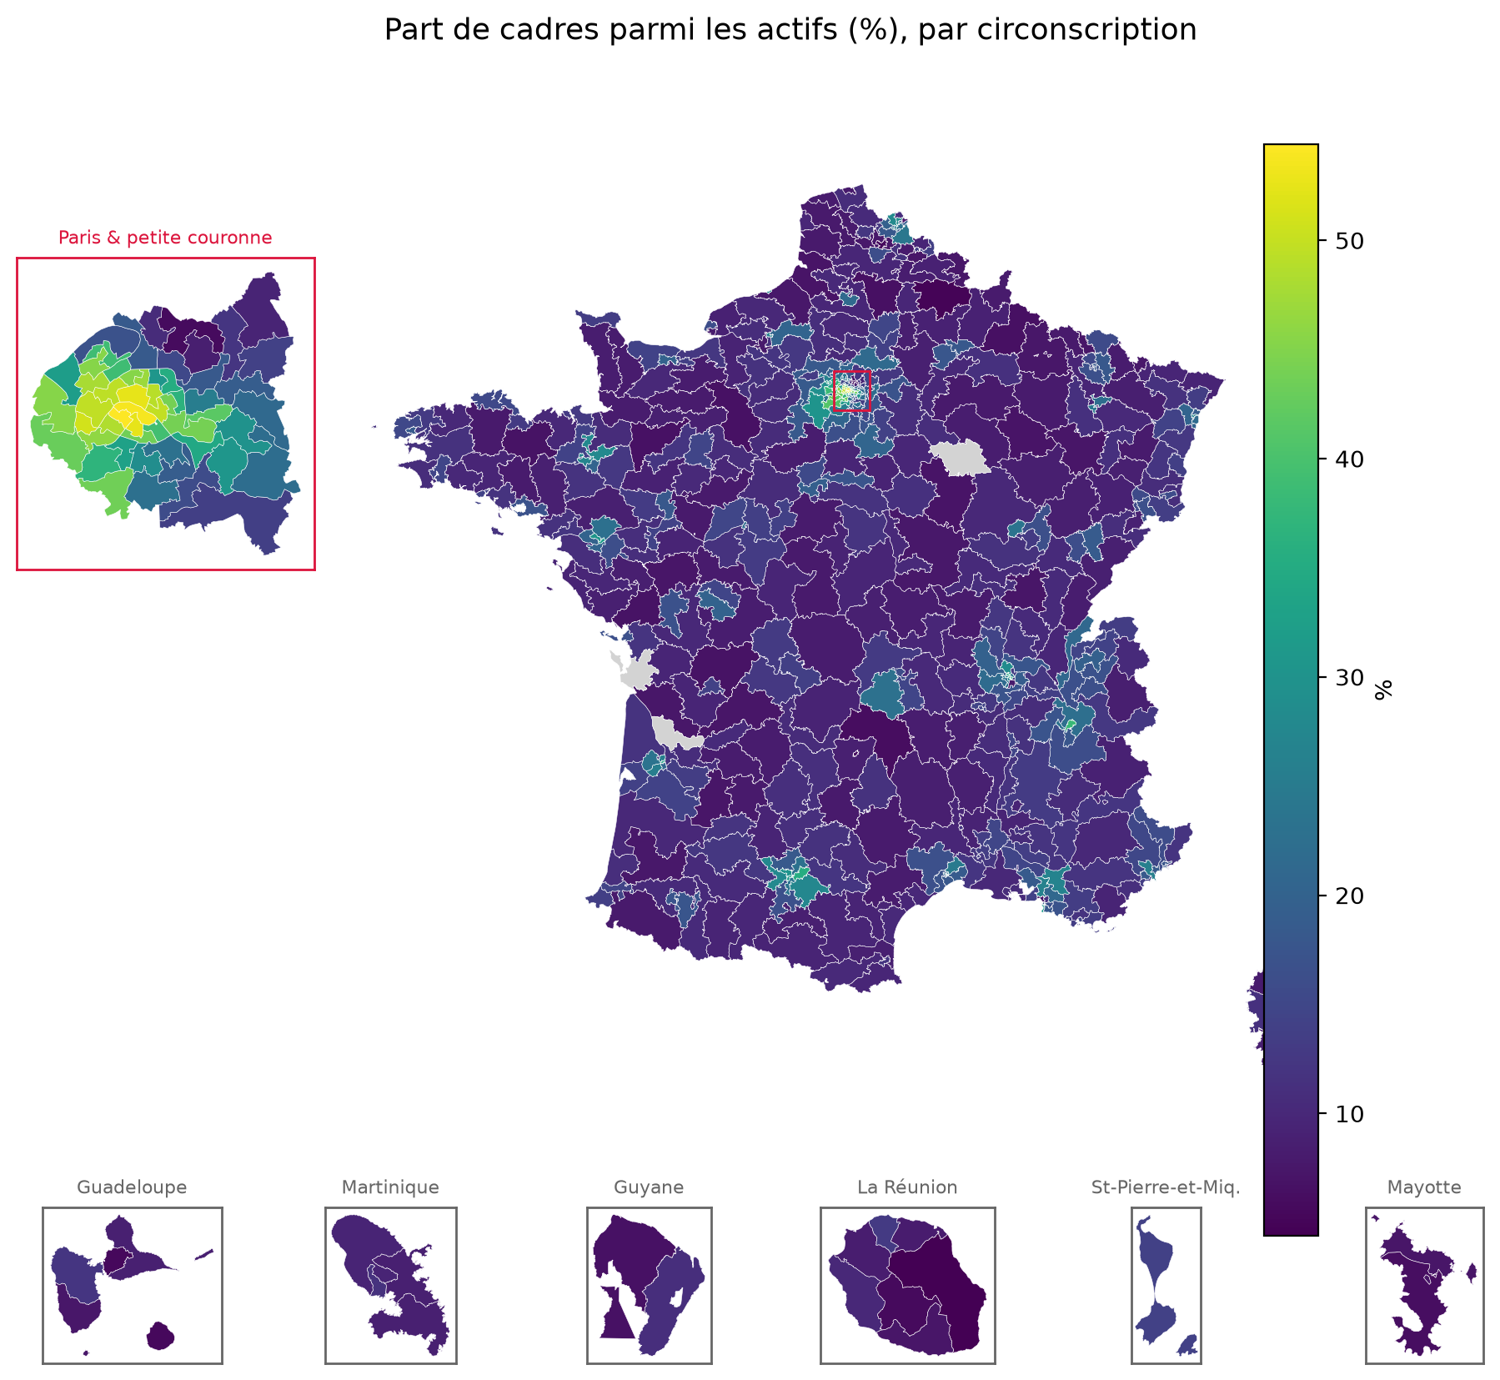

In [ ]:
from cartes import (
    preparer_carte, carte_indicateur, carte_genre, carte_csp, carte_groupes,
)

carte = preparer_carte()
carte_indicateur(carte, "act_cad", "Part de cadres parmi les actifs (%), par circonscription");

La part de cadres parmi les actifs est très concentrée dans l'espace. Dans la grande majorité des circonscriptions, elle est comprise entre 5 % et 15 %, et presque tous les territoires ruraux sont sous les 10 %. Les valeurs élevées se concentrent dans les grandes agglomérations (Lyon, Toulouse, Lille, Nantes, Rennes, Bordeaux, Grenoble, Montpellier, Aix-Marseille, Nice) et, plus encore, à Paris et dans l'ouest de la petite couronne (encart rouge), où la part de cadres dépasse 50 % dans les circonscriptions parisiennes les plus favorisées. Cette carte sert de référence pour les suivantes : c'est elle que l'on compare à la profession des élus (3.4).

## 3.2 Les circonscriptions : part de femmes dans la population

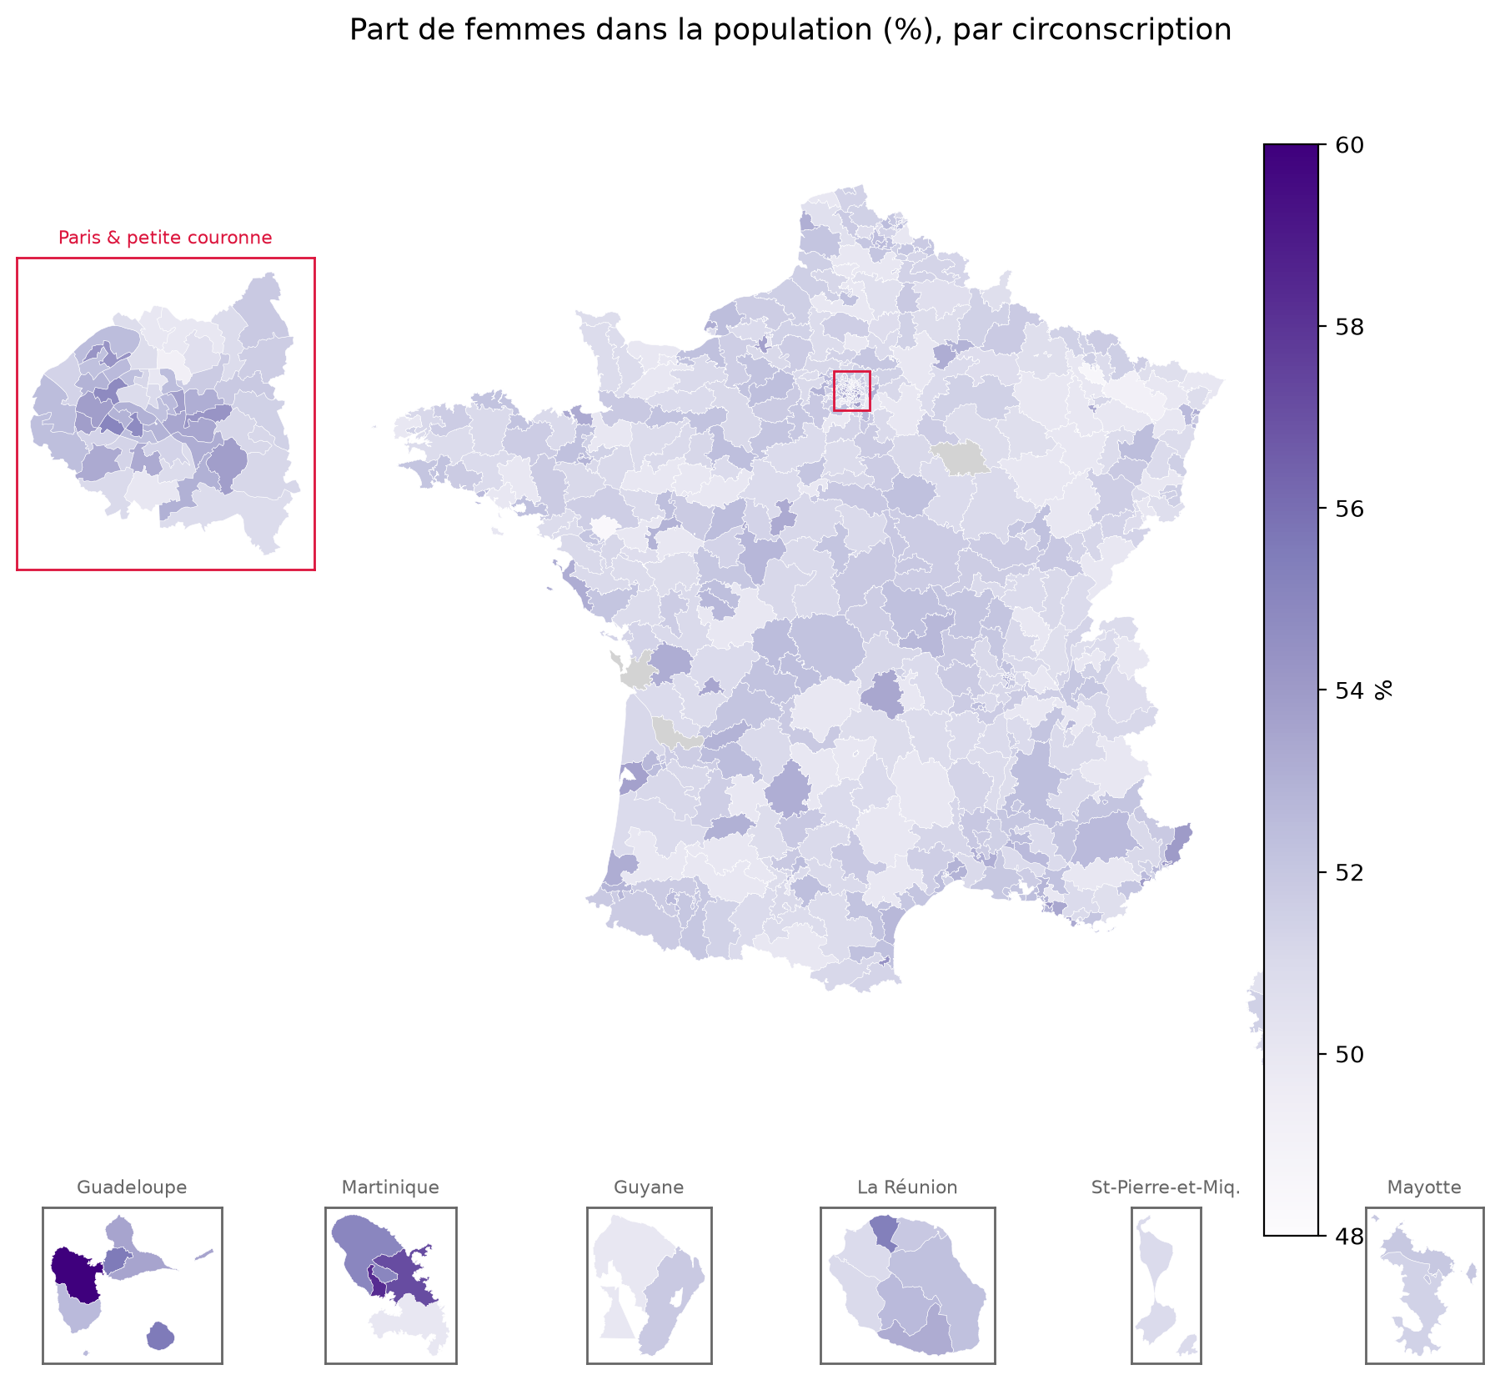

In [ ]:
carte_indicateur(
    carte, "part_femmes", "Part de femmes dans la population (%), par circonscription",
    cmap="Purples",
);

Cette carte donne le point de repère « population » pour la carte du genre des députés (3.3). Elle montre que la part de femmes varie peu en métropole : l'essentiel des circonscriptions se situe entre 50 % et 53 %, avec des valeurs un peu plus élevées dans Paris et la petite couronne (encart) et dans quelques circonscriptions urbaines. Les valeurs les plus fortes (jusqu'à 60 %, extrémité de l'échelle) se trouvent en outre-mer, en Guadeloupe et en Martinique. La population est donc partout à peu près paritaire, voire légèrement féminine, alors que 38 % des députés sont des femmes : **la sous-représentation des femmes à l'Assemblée ne s'explique pas par la démographie des circonscriptions** (voir aussi section 5.2).

*Précaution de lecture.* La table INSEE ne fournit pas la part de femmes : elle est reconstruite à partir des taux d'emploi global, masculin et féminin (formule dans le README). Cette estimation indirecte est instable lorsque les taux d'emploi des hommes et des femmes sont proches, et ne doit pas être lue au dixième de point près. Les écarts entre circonscriptions sont de l'ordre de quelques points, et seuls les grands contrastes sont interprétables.

## 3.3 Les députés : genre

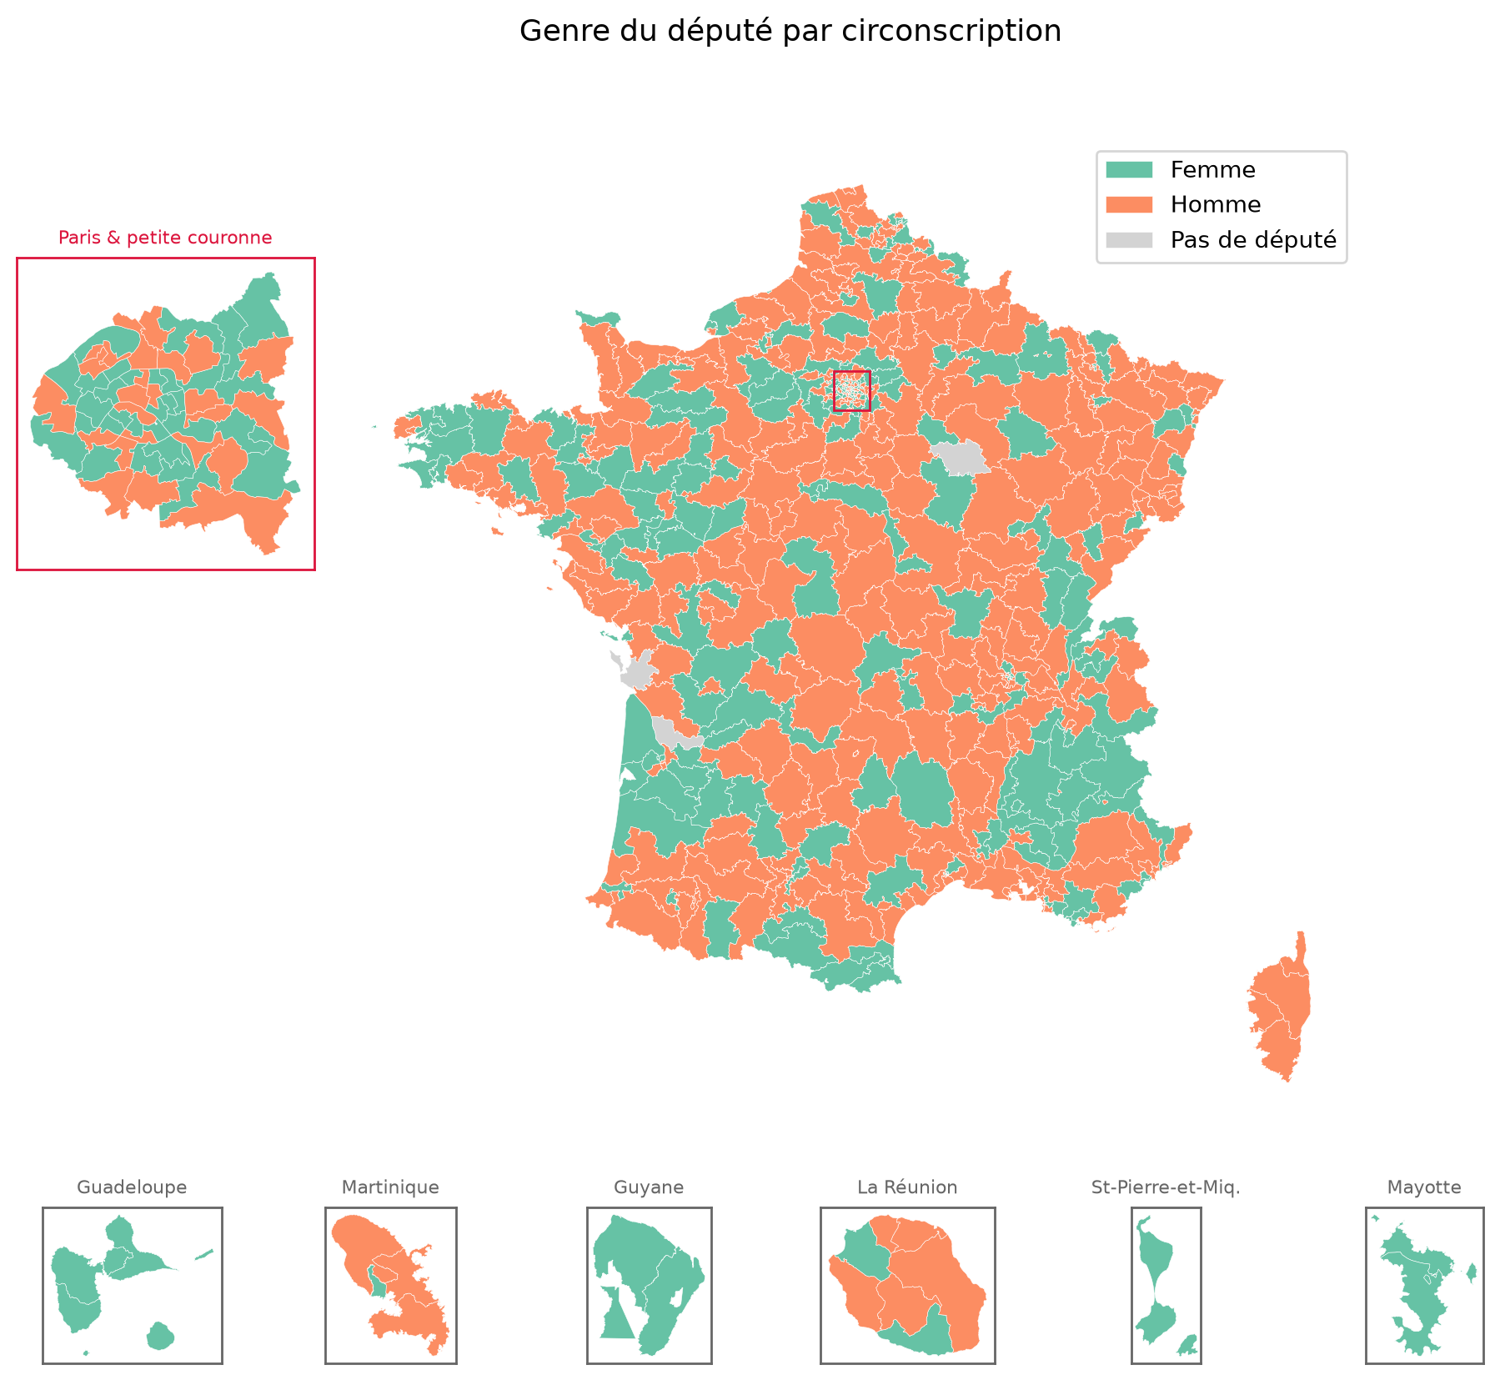

In [ ]:
carte_genre(carte);

La carte du genre des députés fait apparaître des regroupements régionaux. Les circonscriptions dont l'élu est une femme sont nombreuses en Bretagne, sur la façade atlantique du Sud-Ouest, dans les Pyrénées et dans les Alpes, tandis que les députés hommes dominent en Normandie, dans le Nord-Est, dans le Centre, sur une partie du littoral méditerranéen et en Corse. Dans l'encart de Paris et de la petite couronne, les deux genres alternent sans motif spatial net. Outre-mer, les élues sont majoritaires en Guadeloupe, en Guyane, à Saint-Pierre-et-Miquelon et à Mayotte, les élus à La Réunion et en Martinique.

Ces regroupements ne suivent pas la carte de la part de cadres (3.1) : les circonscriptions des députées ne se limitent pas aux grandes agglomérations, ce qui s'accorde avec l'écart modeste mesuré en 2.2. Une explication possible, testée indirectement en 2.2 (écarts intra-groupe) et en 5.2, est que les groupes politiques, inégalement implantés selon les régions (3.5), présentent inégalement de femmes.

## 3.4 Les députés : catégorie socioprofessionnelle

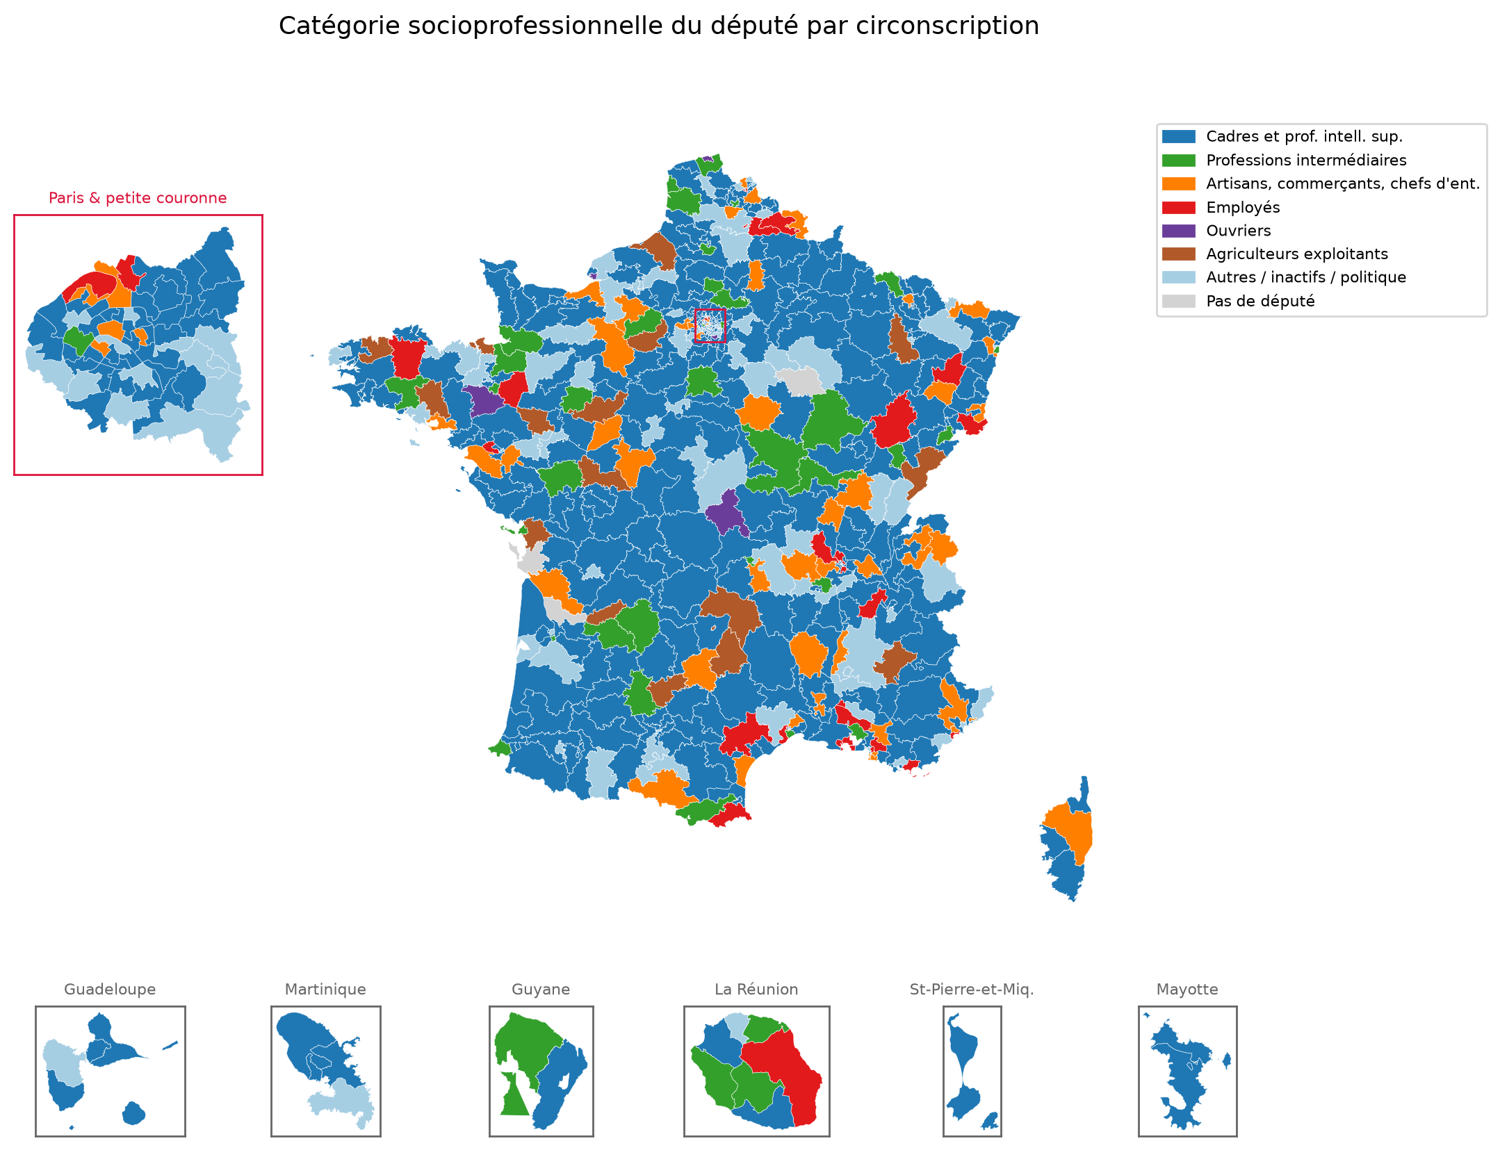

In [ ]:
carte_csp(carte);

La carte des catégories socioprofessionnelles des députés illustre à l'échelle du territoire le résultat de la section 2.3 : **le bleu des cadres et professions intellectuelles supérieures couvre l'essentiel de la France**, aussi bien dans les grandes métropoles que dans les départements ruraux que la carte 3.1 montre pauvres en cadres. Les députés d'autres catégories sont rares et dispersés : employés dans le Nord, en Lorraine, sur le littoral languedocien et à La Réunion ; agriculteurs exploitants dans le Massif central, en Bretagne, en Normandie, en Lorraine et dans les Alpes ; artisans, commerçants et chefs d'entreprise en Corse, dans l'Ouest et dans le Massif central. Les ouvriers n'apparaissent que dans de rares circonscriptions (cinq députés classés), invisibles ou presque à cette échelle. Les professions intermédiaires sont plus présentes dans l'Ouest, le Nord-Est et en Guyane.

Deux enseignements. D'abord, les circonscriptions où l'on trouve des élus non cadres ne sont pas systématiquement celles où la part de cadres est la plus faible : la carte confirme visuellement l'absence de lien significatif mesuré par le test du chi2 (p = 0,45, section 2.3), ce que complète le test de tendance de la section 5.3. Ensuite, les zones « Autres / inactifs / politique » (bleu clair) regroupent des profils que nous ne pouvons pas rattacher à une catégorie INSEE ; elles ne sont pas interprétées.

## 3.5 Les députés : groupe politique

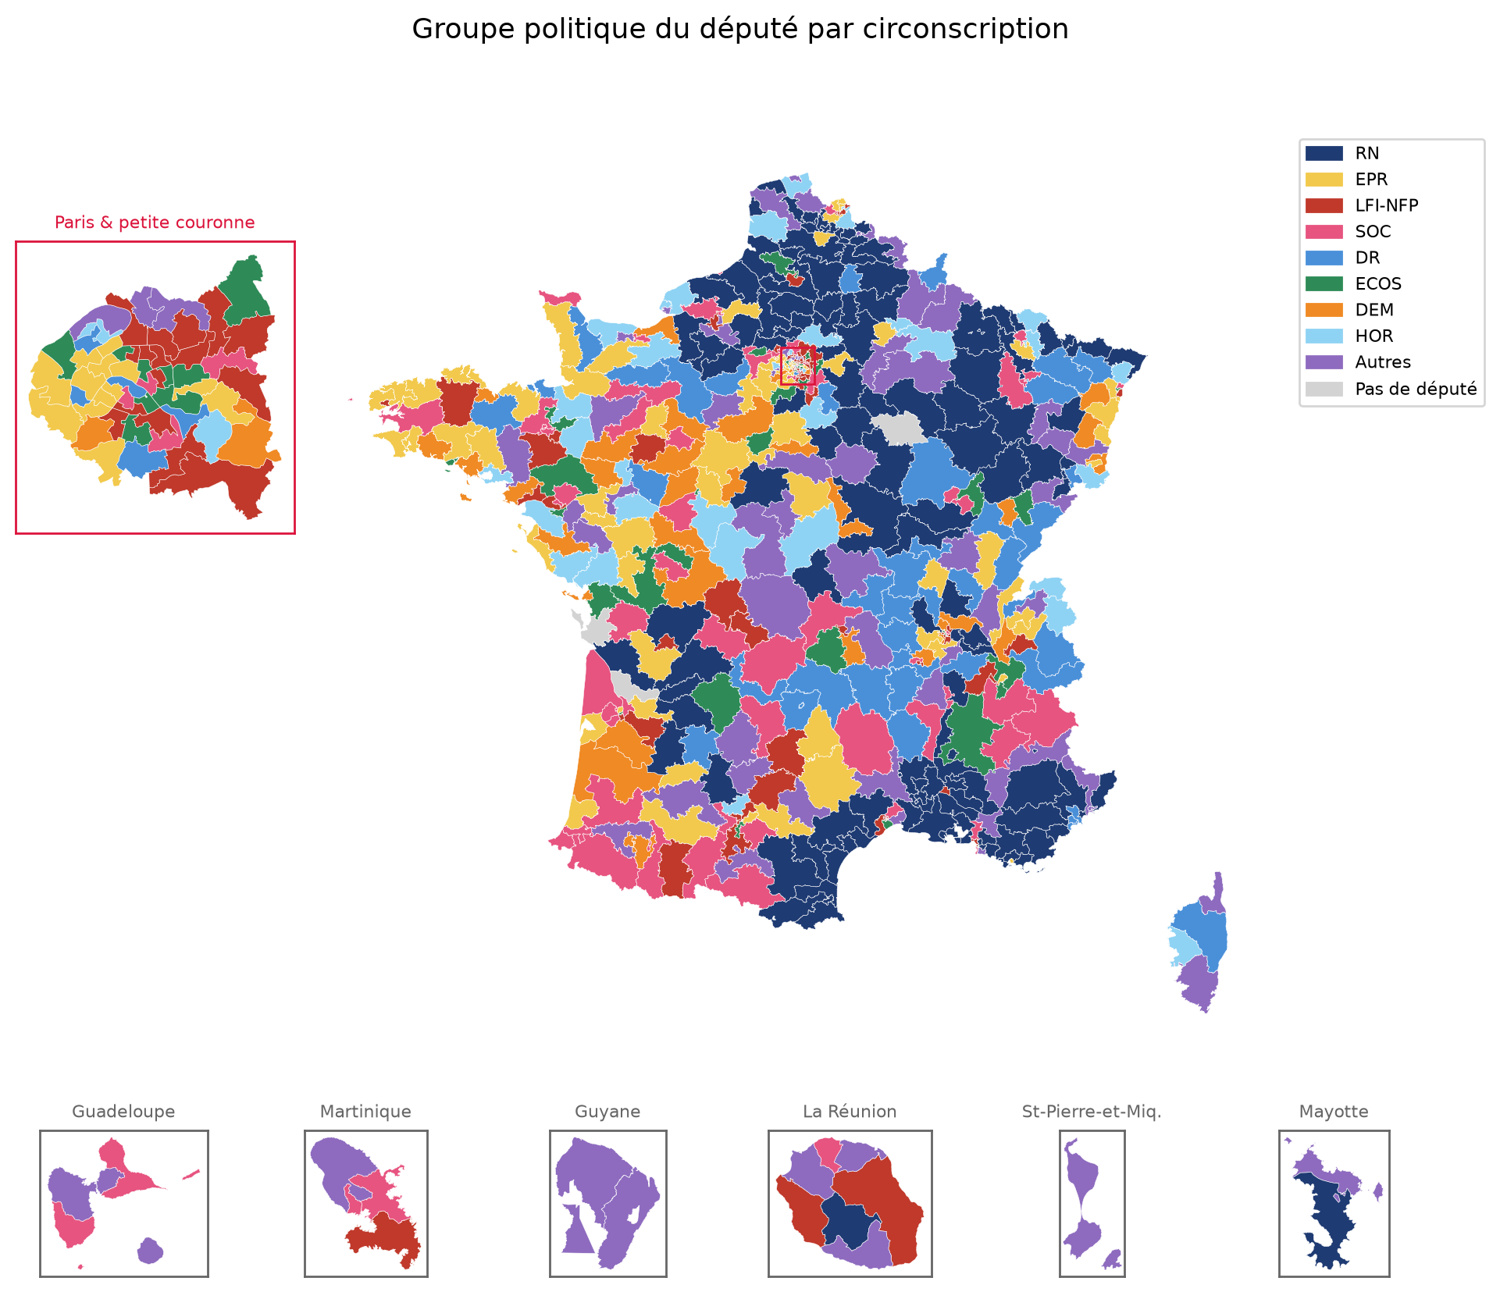

In [ ]:
carte_groupes(carte);

La carte des groupes montre une forte structure géographique. Le RN domine le Nord, le Nord-Est, le Centre et l'arc méditerranéen, du Roussillon à la Côte d'Azur. Le groupe socialiste est concentré dans le Sud-Ouest et le long de la façade atlantique, EPR, DEM et HOR dans l'Ouest et en Bretagne, et les groupes de gauche (LFI-NFP, ECOS) dans les grandes villes et leur périphérie (Paris et Seine-Saint-Denis, agglomérations de Toulouse et de Lyon, Marseille). Dans Paris et la petite couronne, EPR, LFI-NFP et ECOS se partagent les circonscriptions. L'outre-mer relève surtout de la catégorie « Autres », qui regroupe les groupes de moins de 20 députés (LIOT, GDR, UDR, NI), et Mayotte est majoritairement RN.

Cette carte donne un sens visuel au résultat de la section 2.4 : si les groupes sont ancrés dans des territoires différents, un groupe qui présente davantage de femmes ou de cadres se retrouve, par construction, dans des circonscriptions au profil différent. Elle appelle une réserve : en rangeant UDR (allié au RN) et LIOT dans « Autres », la carte atténue légèrement l'étendue de l'ancrage du RN.

# 4. Synthèse des écarts entre élus et population

| Critère | Les députés | La population / les circonscriptions | Écart |
|---|---|---|---|
| Genre | 38,3 % de femmes (220 sur 574) | Population à peu près paritaire (3.2) | Les femmes sont nettement sous-représentées |
| Âge | 52,2 ans en moyenne | Âge médian de la circonscription : 41 ans, enfants inclus | Non comparable en niveau, lien faible en variation (r = 0,18) |
| Cadres | 70,8 % des députés classés | 16,0 % de la population active | + 54,8 points |
| Professions intermédiaires | 8,2 % | 24,6 % | − 16,4 points |
| Employés | 5,5 % | 28,4 % | − 22,8 points |
| Ouvriers | 1,0 % | 21,4 % | − 20,4 points |
| Agriculteurs | 3,3 % | 1,4 % | + 1,8 point |
| Artisans, commerçants, chefs d'entreprise | 11,2 % | 6,3 % | + 4,9 points |

L'Assemblée est **socialement très éloignée** de la population active, et cet éloignement est **uniforme sur le territoire** : il ne dépend pas du profil de la circonscription (2.3, 5.3). Ce qui varie d'une circonscription à l'autre est secondaire : le genre et le groupe politique du député sont associés à des profils de territoires un peu différents (2.2, 2.4), mais ces écarts restent modestes en comparaison.

# 5. Robustesse des résultats

Les résultats précédents reposent sur des tests choisis a priori (Pearson, Mann-Whitney, chi2, Kruskal-Wallis). Pour éviter qu'ils ne dépendent d'un choix méthodologique, cette section les reprend avec des méthodes complémentaires : **intervalles de confiance par bootstrap** (5 000 rééchantillonnages, graine fixée), **correction des tests multiples de Holm**, **tailles d'effet** (d de Cohen, delta de Cliff), **tests de permutation** (qui ne supposent aucune distribution) et **analyses de sensibilité** (que deviennent les résultats si l'on change une hypothèse ?). Toutes les cellules sont déterministes (graine 42).

Les fonctions utilisées ne dépendent que de `numpy`, `pandas` et `scipy` (déjà dans `requirements.txt`).

In [ ]:
from itertools import permutations

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, norm, pearsonr, spearmanr

from descriptif import taux_chomage
from representativite import CSP_LIBELLES, INDICATEURS_INTRA, VARIABLES_GENRE

GRAINE = 42


def holm(pvals):
    """p-values ajustées par la méthode de Holm (contrôle du risque global)."""
    p = np.asarray(pvals, dtype=float)
    ordre = np.argsort(p)
    ajustees = np.empty(len(p))
    maxi = 0.0
    for rang, i in enumerate(ordre):
        maxi = max(maxi, (len(p) - rang) * p[i])
        ajustees[i] = min(1.0, maxi)
    return ajustees


def ic_bootstrap(fonction, *echantillons, n_boot=5000, graine=GRAINE):
    """IC à 95 % (percentiles) d'une statistique, par rééchantillonnage."""
    rng = np.random.default_rng(graine)
    stats = [
        fonction(*[e[rng.integers(0, len(e), len(e))] for e in echantillons])
        for _ in range(n_boot)
    ]
    return np.percentile(stats, [2.5, 97.5])


def ic_bootstrap_paire(fonction, x, y, n_boot=5000, graine=GRAINE):
    """IC à 95 % d'une statistique calculée sur des couples (x, y) : on
    rééchantillonne les couples, pas les deux séries séparément."""
    rng = np.random.default_rng(graine)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        stats.append(fonction(x[i], y[i]))
    return np.percentile(stats, [2.5, 97.5])


def ic_fisher(r, n, niveau=0.95):
    """IC d'une corrélation de Pearson (transformation de Fisher)."""
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    q = norm.ppf(0.5 + niveau / 2)
    return np.tanh(z - q * se), np.tanh(z + q * se)


def ic_wilson(k, n, niveau=0.95):
    """IC de Wilson d'une proportion (fiable même si la part est proche de 0)."""
    z = norm.ppf(0.5 + niveau / 2)
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    demi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return centre - demi, centre + demi

## 5.1 Âge : le lien est-il robuste ?

Trois contrôles : la corrélation de rang de Spearman (insensible à la forme de la relation et aux valeurs extrêmes), un intervalle bootstrap de la corrélation de Pearson, et le même calcul en retirant les 5 % de députés les plus jeunes et les plus âgés.

In [ ]:
metro = comp[~comp["outre_mer"]][["age", "dec50"]].dropna()
age, dec50 = metro["age"].to_numpy(float), metro["dec50"].to_numpy(float)

r_p, p_p = pearsonr(age, dec50)
r_s, p_s = spearmanr(age, dec50)
ic_f = ic_fisher(r_p, len(metro))
ic_b = ic_bootstrap_paire(lambda a, b: np.corrcoef(a, b)[0, 1], age, dec50)

q05, q95 = np.percentile(age, [5, 95])
centre = metro[(metro["age"] >= q05) & (metro["age"] <= q95)]
r_c = pearsonr(centre["age"], centre["dec50"])[0]

robustesse_age = pd.Series({
    "n circonscriptions (métropole)": len(metro),
    "Pearson r": r_p,
    "IC95 % Fisher (bas)": ic_f[0], "IC95 % Fisher (haut)": ic_f[1],
    "IC95 % bootstrap (bas)": ic_b[0], "IC95 % bootstrap (haut)": ic_b[1],
    "Spearman rho": r_s, "p-value Spearman": p_s,
    "r² (variance expliquée)": r_p**2,
    "Pearson r hors 5 % extrêmes": r_c,
})
display(robustesse_age.round(4).to_frame("valeur"))

**Lecture.** Si les deux intervalles (Fisher et bootstrap) restent strictement positifs et que le coefficient de Spearman est du même ordre que celui de Pearson, la conclusion de la section 2.1 est robuste : l'âge du député est faiblement mais réellement associé à l'âge de sa circonscription. L'intervalle de Fisher calculé à la main est d'environ [0,10 ; 0,26] ; la borne supérieure correspond à moins de 7 % de variance expliquée, ce qui ne remet pas en cause le constat d'un lien faible.

## 5.2 Genre : tailles d'effet, intervalles de confiance et correction de Holm

La section 2.2 s'appuyait sur une correction de Bonferroni évaluée à la main. On la remplace par la correction de Holm, uniformément plus puissante, appliquée aux neuf indicateurs, et on ajoute l'intervalle de confiance bootstrap de l'écart de moyennes (pour savoir si l'écart est précisément estimé) et deux tailles d'effet (pour savoir s'il est grand ou petit).

In [ ]:
def genre_robuste(d, n_boot=5000):
    """Écart femmes - hommes par indicateur : IC bootstrap, tailles d'effet, Holm."""
    m = d[~d["outre_mer"]].copy()
    m["taux_chomage"] = taux_chomage(m)
    lignes = []
    for col, libelle in VARIABLES_GENRE.items():
        f = m.loc[m["genre"] == "Femme", col].dropna().to_numpy(float)
        h = m.loc[m["genre"] == "Homme", col].dropna().to_numpy(float)
        u, p = mannwhitneyu(f, h)
        sd = np.sqrt(((len(f) - 1) * f.var(ddof=1) + (len(h) - 1) * h.var(ddof=1))
                     / (len(f) + len(h) - 2))
        bas, haut = ic_bootstrap(lambda a, b: a.mean() - b.mean(), f, h, n_boot=n_boot)
        lignes.append({
            "indicateur": libelle, "ecart": f.mean() - h.mean(),
            "ic95_bas": bas, "ic95_haut": haut,
            "d_cohen": (f.mean() - h.mean()) / sd,
            "delta_cliff": 2 * u / (len(f) * len(h)) - 1,
            "p_value": p,
        })
    t = pd.DataFrame(lignes).set_index("indicateur")
    t["p_holm"] = holm(t["p_value"])
    t["signif_holm_5pct"] = t["p_holm"] < 0.05
    return t


tab_genre_rob = genre_robuste(comp)
display(tab_genre_rob.round(3))

**Lecture.** Le d de Cohen indique la taille de l'écart en écarts-types (0,2 est conventionnellement un petit effet, 0,5 un effet moyen). Le delta de Cliff est la probabilité qu'une circonscription de députée ait une valeur plus élevée qu'une circonscription de député, moins la probabilité inverse : 0 signifie des distributions superposées. Un indicateur est considéré comme établi s'il reste significatif après Holm (`signif_holm_5pct`) **et** si son intervalle bootstrap exclut 0. D'après les écarts observés en 2.2, les tailles d'effet devraient être petites : les groupes de circonscriptions se recouvrent largement, même si les écarts de moyennes sont significatifs.

### Écart intra-groupe : test de permutation

Pour l'écart interne aux groupes (section 2.2), on remplace le test de Mann-Whitney par un **test de permutation stratifié** : on mélange le genre des députés à l'intérieur de chaque groupe politique (ce qui conserve exactement la composition des groupes) et on regarde si l'écart observé sort de la distribution obtenue. C'est le test qui correspond le plus directement à la question « à groupe égal, y a-t-il un écart ? ».

In [ ]:
def permutation_intra_groupe(d, effectif_min=20, n_perm=5000, graine=GRAINE):
    """Écart femmes - hommes net de la moyenne du groupe, p-value par permutation
    du genre à l'intérieur de chaque groupe (statistique bilatérale)."""
    m = d[~d["outre_mer"]]
    tailles = m["groupeAbrev"].value_counts()
    m = m[m["groupeAbrev"].isin(tailles[tailles >= effectif_min].index)]
    rng = np.random.default_rng(graine)
    lignes = []
    for col in INDICATEURS_INTRA:
        s = m[[col, "groupeAbrev", "genre"]].dropna()
        g = s["groupeAbrev"].to_numpy()
        fem = (s["genre"] == "Femme").to_numpy()
        val = s[col].to_numpy(float)
        res = val - s.groupby("groupeAbrev")[col].transform("mean").to_numpy(float)
        indices = [np.flatnonzero(g == k) for k in np.unique(g)]

        def ecart(masque):
            return res[masque].mean() - res[~masque].mean()

        obs = ecart(fem)
        sim = np.empty(n_perm)
        for b in range(n_perm):
            masque = fem.copy()
            for ix in indices:
                masque[ix] = rng.permutation(fem[ix])
            sim[b] = ecart(masque)
        lignes.append({
            "indicateur": VARIABLES_GENRE[col], "ecart_intra_groupe": obs,
            "p_permutation": (1 + np.sum(np.abs(sim) >= abs(obs))) / (n_perm + 1),
        })
    t = pd.DataFrame(lignes).set_index("indicateur")
    t["p_holm"] = holm(t["p_permutation"])
    return t


tab_perm = permutation_intra_groupe(comp)
display(tab_perm.round(4))

**Lecture.** Les p-values de permutation doivent concorder avec celles de Mann-Whitney du tableau 2.2 (0,001 pour la part d'ouvriers ; 0,046 à 0,075 pour les autres indicateurs). La section 2.2 conclut que seul l'écart sur la part d'ouvriers résiste à la correction : la colonne `p_holm` permet de le vérifier sans seuil calculé à la main. Une concordance entre les deux tests rend ce résultat indépendant du choix de test.

### Population contre élus : le genre des députés suit-il la part de femmes de la circonscription ?

La carte 3.2 suggère que la part de femmes dans la population est presque uniforme. On vérifie, avec la table cartographique, que le genre du député n'est pas lié à cette part, et on compare la part de femmes parmi les députés à celle de la population.

In [ ]:
c = carte[~carte["code_circo"].str[:2].isin(["97", "98", "99"])]
c = c.dropna(subset=["genre", "part_femmes"])
pf_f = c.loc[c["genre"] == "Femme", "part_femmes"].to_numpy(float)
pf_h = c.loc[c["genre"] == "Homme", "part_femmes"].to_numpy(float)
bas, haut = ic_bootstrap(lambda a, b: a.mean() - b.mean(), pf_f, pf_h)

k, n = int((c["genre"] == "Femme").sum()), len(c)
print(f"Part de femmes parmi les députés (métropole) : {k / n * 100:.1f} % "
      f"(IC95 % Wilson : {ic_wilson(k, n)[0] * 100:.1f} - {ic_wilson(k, n)[1] * 100:.1f})")
print(f"Part de femmes dans la population (moyenne des circonscriptions) : "
      f"{c['part_femmes'].mean():.1f} %")
print(f"Part de femmes de la circonscription, députées - députés : "
      f"{pf_f.mean() - pf_h.mean():+.2f} point (IC95 % bootstrap : {bas:+.2f} ; {haut:+.2f}), "
      f"p Mann-Whitney = {mannwhitneyu(pf_f, pf_h).pvalue:.3f}")

**Lecture.** L'écart entre la part de femmes parmi les élus et dans la population est le résultat principal de ce volet : il ne dépend pas de la composition démographique des circonscriptions (écart de part de femmes entre circonscriptions de députées et de députés proche de zéro si l'intervalle encadre 0). Rappel : la part de femmes dans la population est une estimation indirecte (voir 3.2) ; le constat d'une sous-représentation est très peu sensible à cette imprécision, vu l'écart de plus de dix points.

## 5.3 Professions : sensibilité au recodage et test de tendance

**Intervalles de confiance.** Les parts de députés par catégorie reposent sur 490 députés classés. L'intervalle de Wilson à 95 % donne notamment, pour les cadres, [66,6 % ; 74,7 %] autour de 70,8 %, soit un intervalle qui ne se rapproche même pas des 16,0 % de la population active. Pour les ouvriers (5 députés), l'intervalle est [0,4 % ; 2,4 %], très loin des 21,4 % d'ouvriers parmi les actifs.

**Sensibilité au recodage.** Le recodage des professions est en partie subjectif (33 libellés ambigus non classés, 29 personnes sans activité ou retraitées, 22 collaborateurs politiques). On borne l'effet de ces choix par des scénarios extrêmes :

| Scénario | Part de cadres parmi les députés |
|---|---|
| Référence : 490 députés classés | 347 / 490 = 70,8 % |
| Les 33 libellés non classés sont tous des non-cadres | 347 / 523 = 66,3 % |
| Les 33 libellés non classés sont tous des cadres | 380 / 523 = 72,7 % |
| Tous les 574 députés au dénominateur (inactifs et politiques comptés non-cadres) | 347 / 574 = 60,5 % |

Dans le scénario le plus défavorable à notre conclusion (pires hypothèses simultanées), la part de cadres reste de **60,5 %, soit près de quatre fois celle de la population active** (16,0 %). Le résultat de la section 2.3 ne dépend donc pas du recodage. Le code ci-dessous recalcule ces valeurs depuis les données.

In [ ]:
def sensibilite_csp(deputes_csp):
    """Part de députés cadres : IC de Wilson et scénarios extrêmes de recodage."""
    classes = deputes_csp[deputes_csp["csp_depute"].isin(CSP_LIBELLES)]
    k, n = int((classes["csp_depute"] == "cad").sum()), len(classes)
    nc = int((deputes_csp["csp_depute"] == "non_classe").sum())
    bas, haut = ic_wilson(k, n)
    return pd.Series({
        "députés classés": n,
        "cadres (référence, %)": k / n * 100,
        "IC95 % Wilson bas (%)": bas * 100, "IC95 % Wilson haut (%)": haut * 100,
        "non classés": nc,
        "borne basse : non classés = non-cadres (%)": k / (n + nc) * 100,
        "borne haute : non classés = cadres (%)": (k + nc) / (n + nc) * 100,
        "pire cas : tous les députés au dénominateur (%)": k / len(deputes_csp) * 100,
    })


display(sensibilite_csp(ajouter_categorie_job(deputes)).round(1).to_frame("valeur"))

# Intervalles de Wilson pour toutes les catégories
classes = ajouter_categorie_job(deputes)
classes = classes[classes["csp_depute"].isin(CSP_LIBELLES)]
lignes = []
for cle, libelle in CSP_LIBELLES.items():
    k, n = int((classes["csp_depute"] == cle).sum()), len(classes)
    bas, haut = ic_wilson(k, n)
    lignes.append({"catégorie": libelle, "effectif": k, "part_deputes_%": k / n * 100,
                   "ic95_bas_%": bas * 100, "ic95_haut_%": haut * 100,
                   "part_pop_active_%": tab_csp.loc[libelle, "population_active"]})
display(pd.DataFrame(lignes).set_index("catégorie").round(1))

**Test de tendance : la part de députés cadres augmente-t-elle avec la part de cadres de la circonscription ?** Le test du chi2 de la section 2.3 compare quatre quartiles sans tenir compte de leur ordre ; il est peu puissant contre une tendance progressive. Le test de tendance de Cochran-Armitage exploite l'ordre des quartiles. À partir des effectifs du tableau 2.3 (79 cadres sur 120, 79 sur 111, 79 sur 112, 86 sur 114), la statistique vaut z ≈ 1,50 (p ≈ 0,13) et l'écart entre le quartile le plus riche en cadres et le plus pauvre est de + 9,6 points avec un intervalle de confiance à 95 % de [− 2,0 ; + 21,2]. Le sens de l'écart est positif, mais il n'est pas significatif : il faut en conclure que **nous ne pouvons pas affirmer que le profil de la circonscription influe sur la profession de son député, et surtout que, même dans le quartile le moins doté, les députés cadres sont deux sur trois** (65,8 %). La non-significativité vient de l'effectif (environ 115 députés par quartile) : on ne peut exclure une dépendance modeste (jusqu'à environ 20 points entre extrêmes), mais pas non plus la présenter comme établie.

In [ ]:
def tendance_cadres(d_csp):
    """Test de tendance de Cochran-Armitage sur les quartiles de part de cadres
    de la circonscription (métropole, députés classés), et écart Q4 - Q1."""
    m = d_csp[(~d_csp["outre_mer"]) & d_csp["csp_depute"].isin(CSP_LIBELLES)].copy()
    m["q"] = pd.qcut(m["act_cad"], 4, labels=False) + 1
    est_cad = (m["csp_depute"] == "cad").astype(int)
    k = est_cad.groupby(m["q"]).sum().to_numpy(float)
    n = est_cad.groupby(m["q"]).count().to_numpy(float)
    x = np.arange(1, 5, dtype=float)
    p = k.sum() / n.sum()
    t = (x * (k - n * p)).sum()
    v = p * (1 - p) * ((n * x**2).sum() - (n * x).sum() ** 2 / n.sum())
    z = t / np.sqrt(v)
    p1, p4 = k[0] / n[0], k[3] / n[3]
    se = np.sqrt(p1 * (1 - p1) / n[0] + p4 * (1 - p4) / n[3])
    return pd.Series({
        "z (tendance)": z, "p-value bilatérale": 2 * norm.sf(abs(z)),
        "écart Q4 - Q1 (points)": (p4 - p1) * 100,
        "IC95 % bas": (p4 - p1 - 1.96 * se) * 100,
        "IC95 % haut": (p4 - p1 + 1.96 * se) * 100,
    })


display(tendance_cadres(comp_csp).round(3).to_frame("valeur"))

## 5.4 Groupes politiques : permutation exacte et retrait successif

La corrélation de Spearman entre la part de femmes et la part moyenne de cadres des circonscriptions (ρ = 0,91) ne porte que sur **huit groupes**. Sa p-value (0,002) repose sur une approximation asymptotique peu fiable à si petit effectif. Avec huit groupes, il est possible de calculer la **p-value exacte** en énumérant les 8! = 40 320 appariements possibles. On vérifie aussi que le résultat ne dépend pas d'un groupe unique en retirant chaque groupe à tour de rôle.

In [ ]:
def spearman_exact(tab, x="part_cadres_circo", y="part_femmes"):
    """Spearman entre deux colonnes d'un tableau par groupe : p-value exacte
    (énumération de toutes les permutations) et retrait successif de chaque groupe."""
    rx = tab[x].rank().to_numpy()
    ry = tab[y].rank().to_numpy()
    rho = np.corrcoef(rx, ry)[0, 1]
    tous = np.array([np.corrcoef(rx, ry[list(p)])[0, 1] for p in permutations(range(len(ry)))])
    p_exact = np.mean(np.abs(tous) >= abs(rho) - 1e-12)
    sans = {g: spearmanr(tab.drop(g)[x], tab.drop(g)[y])[0] for g in tab.index}
    return rho, p_exact, pd.Series(sans, name="rho sans ce groupe")


rho, p_exact, sans_groupe = spearman_exact(tab_groupes)
print(f"rho de Spearman = {rho:.2f} ; p-value exacte (8! permutations) = {p_exact:.4f}")
print(f"rho en retirant chaque groupe : min {sans_groupe.min():.2f}, max {sans_groupe.max():.2f}")
display(sans_groupe.round(2).to_frame())

**Résultats.** Sur les huit groupes, la p-value exacte est de **0,003** (contre 0,002 par l'approximation asymptotique) : la conclusion ne change pas. En retirant successivement chacun des huit groupes, la corrélation reste comprise entre **0,86** (sans LFI-NFP) et **0,93** (sans DEM) : aucun groupe ne porte à lui seul le résultat. La corrélation de Pearson sur les mêmes huit points est de 0,89 (p = 0,003), ce qui exclut qu'il s'agisse d'un artefact du passage aux rangs.

Au niveau des groupes, la relation est donc **forte, stable et non due à un cas particulier**. Elle reste cependant une corrélation sur huit moyennes de groupe : elle ne dit pas que, dans un groupe donné, les députées sont élues dans des circonscriptions plus riches en cadres (c'est le sujet de la section 2.2, où l'écart intra-groupe est nettement plus faible), et ne prouve aucune causalité.

# 6. Conclusion

**Les députés ne sont pas représentatifs de leurs électeurs sur le plan socioprofessionnel, et cet écart est très robuste.** Sept députés classés sur dix sont cadres ou de profession intellectuelle supérieure, contre un actif sur six. Employés et ouvriers, qui forment près de la moitié de la population active, représentent 6,5 % des députés classés. Ce résultat tient dans tous les scénarios extrêmes de recodage des professions (la part de cadres reste de 60,5 % à 72,7 %), il ne dépend pas du profil de la circonscription (même dans les territoires les moins dotés en cadres, les élus sont très majoritairement cadres), et la carte 3.4 le montre sur l'ensemble du territoire.

**Le genre est le second écart net.** 38 % des députés sont des femmes alors que la population est à peu près paritaire (cartes 3.2 et 3.3). Les circonscriptions des députées sont un peu plus urbaines et favorisées que celles des députés : l'écart est modeste, une partie seulement s'explique par la géographie des partis, et seul celui sur la part d'ouvriers résiste à la correction des tests multiples une fois le groupe politique contrôlé.

**L'âge du député ressemble peu à celui de ses électeurs** : la corrélation est faible (r = 0,18, soit environ 3 % de variance expliquée), significative mais sans portée pratique.

**Le groupe politique structure le profil des circonscriptions** (Kruskal-Wallis, p ≈ 7·10⁻²³ ; carte 3.5) : les groupes qui comptent le plus de femmes sont ceux dont les circonscriptions comptent le plus de cadres (ρ = 0,91, p exact = 0,003, stable au retrait de n'importe quel groupe). C'est la principale piste d'explication des écarts de genre entre circonscriptions.

## Limites

- **Données de 2022 et députés de 2026.** Les indicateurs INSEE datent de 2022 et décrivent les circonscriptions telles qu'elles étaient alors ; la composition de l'Assemblée est celle du fichier téléchargé le 14 novembre 2026. Trois circonscriptions sans député (Aube 2e, Charente-Maritime 5e, Gironde 11e) sont absentes des comparaisons.
- **Profession déclarée.** La catégorie socioprofessionnelle repose sur la profession déclarée par les députés avant leur élection, parfois valorisée, et sur un recodage en partie subjectif (5,7 % de libellés non classés). L'analyse de sensibilité (5.3) borne l'effet de ce choix mais ne l'élimine pas. Les cinq ouvriers et les seize agriculteurs sont trop peu nombreux pour des conclusions fines.
- **Comparaison âge.** L'âge INSEE inclut les enfants : seule la variation entre circonscriptions est interprétable, pas le niveau.
- **Part de femmes.** Reconstruite indirectement à partir des taux d'emploi (3.2) ; ne doit pas être lue au dixième de point près.
- **Population de référence.** La population active comprend des personnes qui ne sont pas électrices (étrangers, mineurs actifs) et ne tient pas compte de l'abstention ; nous comparons des élus à la population active, pas à l'électorat.
- **Niveau d'analyse.** Les corrélations décrivent des circonscriptions et des groupes, non des individus (risque d'erreur écologique). Les circonscriptions voisines se ressemblent : leur indépendance statistique n'est pas parfaite, ce qui tend à rendre les p-values un peu optimistes.
- **Pas de causalité.** Nous mesurons des écarts et des associations, pas leurs causes (sélection par les partis, choix des électeurs, effet de l'investiture).
- **Outre-mer et étranger.** Exclus des comparaisons de genre (profils atypiques, indicateurs manquants) ; sept circonscriptions d'outre-mer ne sont pas cartographiées.

## Pistes

Contrôler l'ancienneté du mandat et le type de scrutin dans l'écart de genre (section 2.2), ajouter des indicateurs électoraux (participation, résultats du premier tour) pour passer de la population à l'électorat, et reprendre l'analyse avec le recensement 2022 par circonscription lorsque l'INSEE le publiera avec les nouveaux découpages.

# Annexe : reproduire le rapport

    pip install -r requirements.txt
    python lancer_extraction.py   # télécharge et nettoie les données
    python jointures.py           # joint députés et indicateurs INSEE
    python cartes.py              # produit les cinq cartes

Puis *Kernel > Restart & Run All*. Toutes les procédures aléatoires (bootstrap, permutations) utilisent la graine 42 et sont donc reproductibles.